# 03 | Modelos, búsqueda de hiperparámetros y evaluación final
**Grupo 6 · Machine Learning · porcentaje de propina en taxis amarillos de NYC (ene-abr 2026)**

Los modelos se entrenan con `python main.py --data-dir Data` (etapas `validacion` y `test`, código en `src/train.py`).
Este notebook **lee los resultados guardados** en `outputs/` y `reports/figures/`, para que el notebook y el script no puedan
desincronizarse. Si se vuelve a ejecutar el pipeline, basta con volver a correr este notebook.

| Conjunto | Periodo | Uso |
|---|---|---|
| Ajuste de la búsqueda | enero (muestra) | entrenar cada configuración candidata |
| Validación de la búsqueda | febrero (muestra) | elegir la mejor configuración de cada familia |
| Entrenamiento | enero + febrero (400 000 viajes por mes) | ajustar las configuraciones elegidas |
| Validación | marzo completo | comparar familias y elegir el modelo final |
| Test | abril completo | evaluación **única**, con el modelo reentrenado en enero-marzo |

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT, FIG = ROOT / 'outputs', ROOT / 'reports' / 'figures'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
assert (OUT / 'metrics_validacion.json').exists(), 'Ejecuta antes: python main.py --data-dir Data'
val = json.loads((OUT / 'metrics_validacion.json').read_text(encoding='utf-8'))
test = json.loads((OUT / 'metrics_test.json').read_text(encoding='utf-8')) if (OUT / 'metrics_test.json').exists() else None

## 1. Modelos comparados

| Nombre | Familia | Notas |
|---|---|---|
| `baseline_media`, `baseline_mediana` | constante | Mismas constantes de la entrega 1 (todas las etiquetas de ene-feb) |
| `baseline_lineal` | lineal | Regresión lineal de la entrega 1 sin cambios (`src/model.py`, muestra 5%) |
| `ridge` | lineal regularizado, pérdida cuadrática | Todas las variables, escaladas |
| `lineal_absoluto` | lineal regularizado, pérdida absoluta | `SGDRegressor(loss='epsilon_insensitive', epsilon=0)` = regresión L1 |
| `random_forest` | bagging de árboles | 60 árboles, 150 000 filas por árbol |
| `hgb_absoluto` | gradient boosting, pérdida absoluta | `HistGradientBoostingRegressor(loss='absolute_error')` |
| `hgb_cuadratico` | gradient boosting, pérdida cuadrática | igual, con `squared_error` |

Todos los modelos nuevos comparten el preprocesamiento de `src/features.py` y el envoltorio `ClippedTargetRegressor`, que recorta la
etiqueta **de entrenamiento** en su cuantil 0.999 y no permite predicciones negativas. Validación y test usan la etiqueta original.

## 2. Búsqueda de hiperparámetros (enero → febrero)

Se usa un corte temporal interno, sin tocar marzo: cada configuración se ajusta con enero y se mide con febrero. La rejilla de
ridge y lineal absoluto es completa; en random forest y boosting se toma una muestra aleatoria (semilla 42) del espacio.

,modelo,familia,params,MAE_pp,seg
0,ridge,lineal regularizado (pérdida cuadrática),"{""alpha"": 0.1}",7.5486,2.4
1,ridge,lineal regularizado (pérdida cuadrática),"{""alpha"": 1.0}",7.5487,2.4
2,ridge,lineal regularizado (pérdida cuadrática),"{""alpha"": 10.0}",7.5492,1.9
3,ridge,lineal regularizado (pérdida cuadrática),"{""alpha"": 100.0}",7.5501,2.0
4,ridge,lineal regularizado (pérdida cuadrática),"{""alpha"": 1000.0}",7.5486,2.2
5,lineal_absoluto,lineal regularizado (pérdida absoluta),"{""alpha"": 1e-06}",6.6432,5.5
6,lineal_absoluto,lineal regularizado (pérdida absoluta),"{""alpha"": 1e-05}",6.6438,6.0
7,lineal_absoluto,lineal regularizado (pérdida absoluta),"{""alpha"": 0.0001}",6.6427,5.5
8,lineal_absoluto,lineal regularizado (pérdida absoluta),"{""alpha"": 0.001}",6.6669,5.8
9,random_forest,bagging de árboles,"{""min_samples_leaf"": 20, ""max_features"": 0.3, ...",7.4667,17.8


,modelo,params,MAE_pp
17,hgb_absoluto,"{""min_samples_leaf"": 50, ""max_leaf_nodes"": 31,...",6.4145
7,lineal_absoluto,"{""alpha"": 0.0001}",6.6427
9,random_forest,"{""min_samples_leaf"": 20, ""max_features"": 0.3, ...",7.4667
20,hgb_cuadratico,"{""min_samples_leaf"": 50, ""max_leaf_nodes"": 31,...",7.4721
0,ridge,"{""alpha"": 0.1}",7.5486


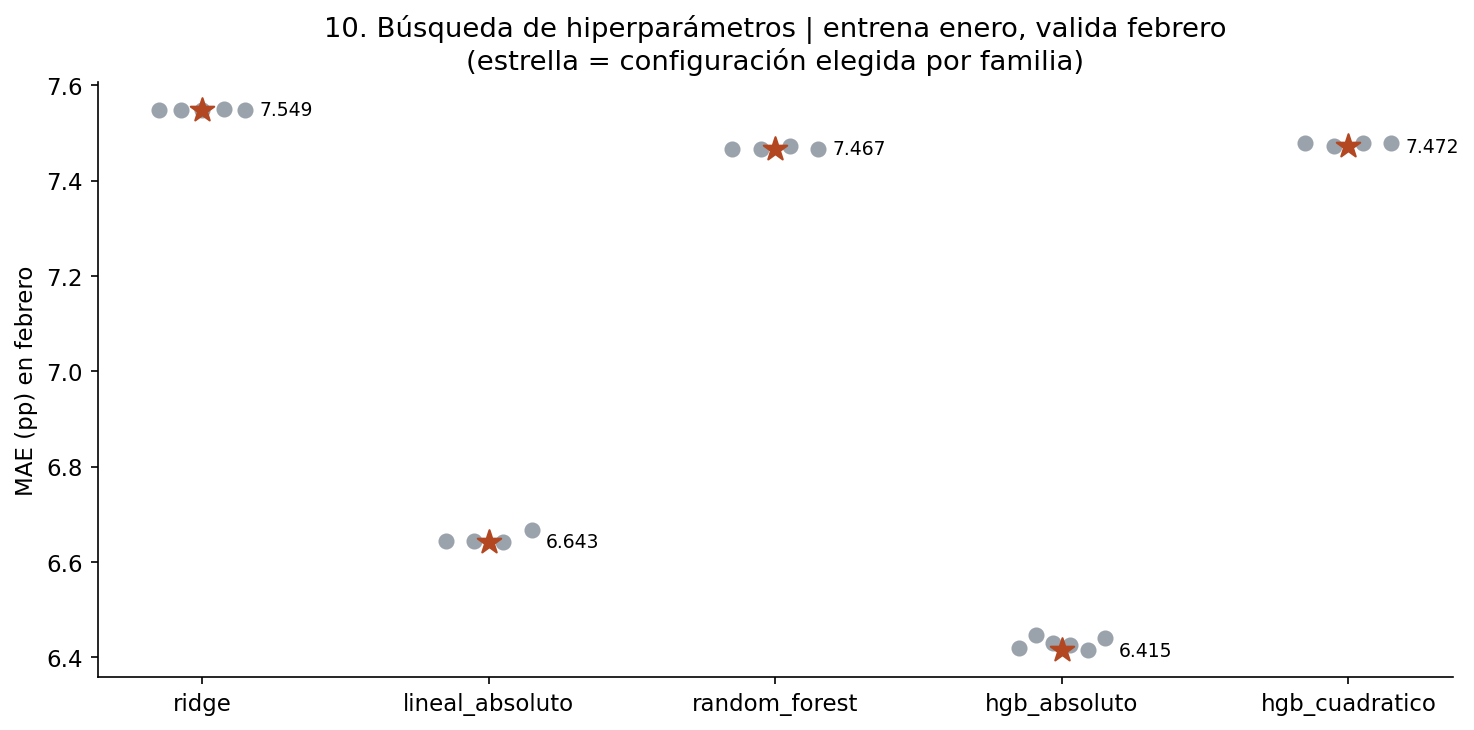

In [2]:
search = pd.read_csv(OUT / 'busqueda_hiperparametros.csv')
display(search)
display(search.loc[search.groupby('modelo').MAE_pp.idxmin(), ['modelo', 'params', 'MAE_pp']].sort_values('MAE_pp'))
display(Image(filename=str(FIG / '10_busqueda_hiperparametros.png')))

Dentro de cada familia, los hiperparámetros cambian el MAE en centésimas o pocas décimas de punto. La diferencia grande está **entre
funciones de pérdida**: las configuraciones con pérdida absoluta quedan alrededor de 1 pp por debajo de las de pérdida cuadrática.

## 3. Comparación en validación (marzo completo)

Modelo elegido (menor MAE en marzo): hgb_absoluto {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'learning_rate': 0.2, 'l2_regularization': 0.0}
Mejora frente al baseline lineal: 16.08 %
Mejora frente a la mediana: 34.81 %


,n,MAE_pp,RMSE_pp,R2,MedAE_pp,P90_AE_pp,RMSE_pp_tarifa_ge_1,n_entrenamiento,fit_seg,mejora_MAE_vs_lineal_%
baseline_media,2565402.0,9.7479,107.6096,-0.000006,6.6268,25.3567,25.3268,4225076.0,NaN,-29.562582
baseline_mediana,2565402.0,9.6848,107.6168,-0.00014,5.9898,26.3758,25.3619,4225076.0,NaN,-28.723899
baseline_lineal,2565402.0,7.5237,107.2835,0.006047,4.3274,17.3505,24.0122,211254.0,NaN,0.0
ridge,2565402,7.4818,107.1408,0.008688,3.9915,17.0808,23.9262,800000,6.3,0.556907
lineal_absoluto,2565402,6.532,105.7836,0.033644,0.9771,18.9481,24.0777,800000,17.5,13.181015
random_forest,2565402,7.4227,107.1764,0.00803,3.9196,16.9289,23.6321,800000,26.4,1.342425
hgb_absoluto,2565402,6.3139,107.2321,0.006999,0.1031,19.1853,23.9557,800000,94.8,16.079854
hgb_cuadratico,2565402,7.4126,107.1535,0.008453,3.9245,16.9051,23.5159,800000,42.8,1.476667


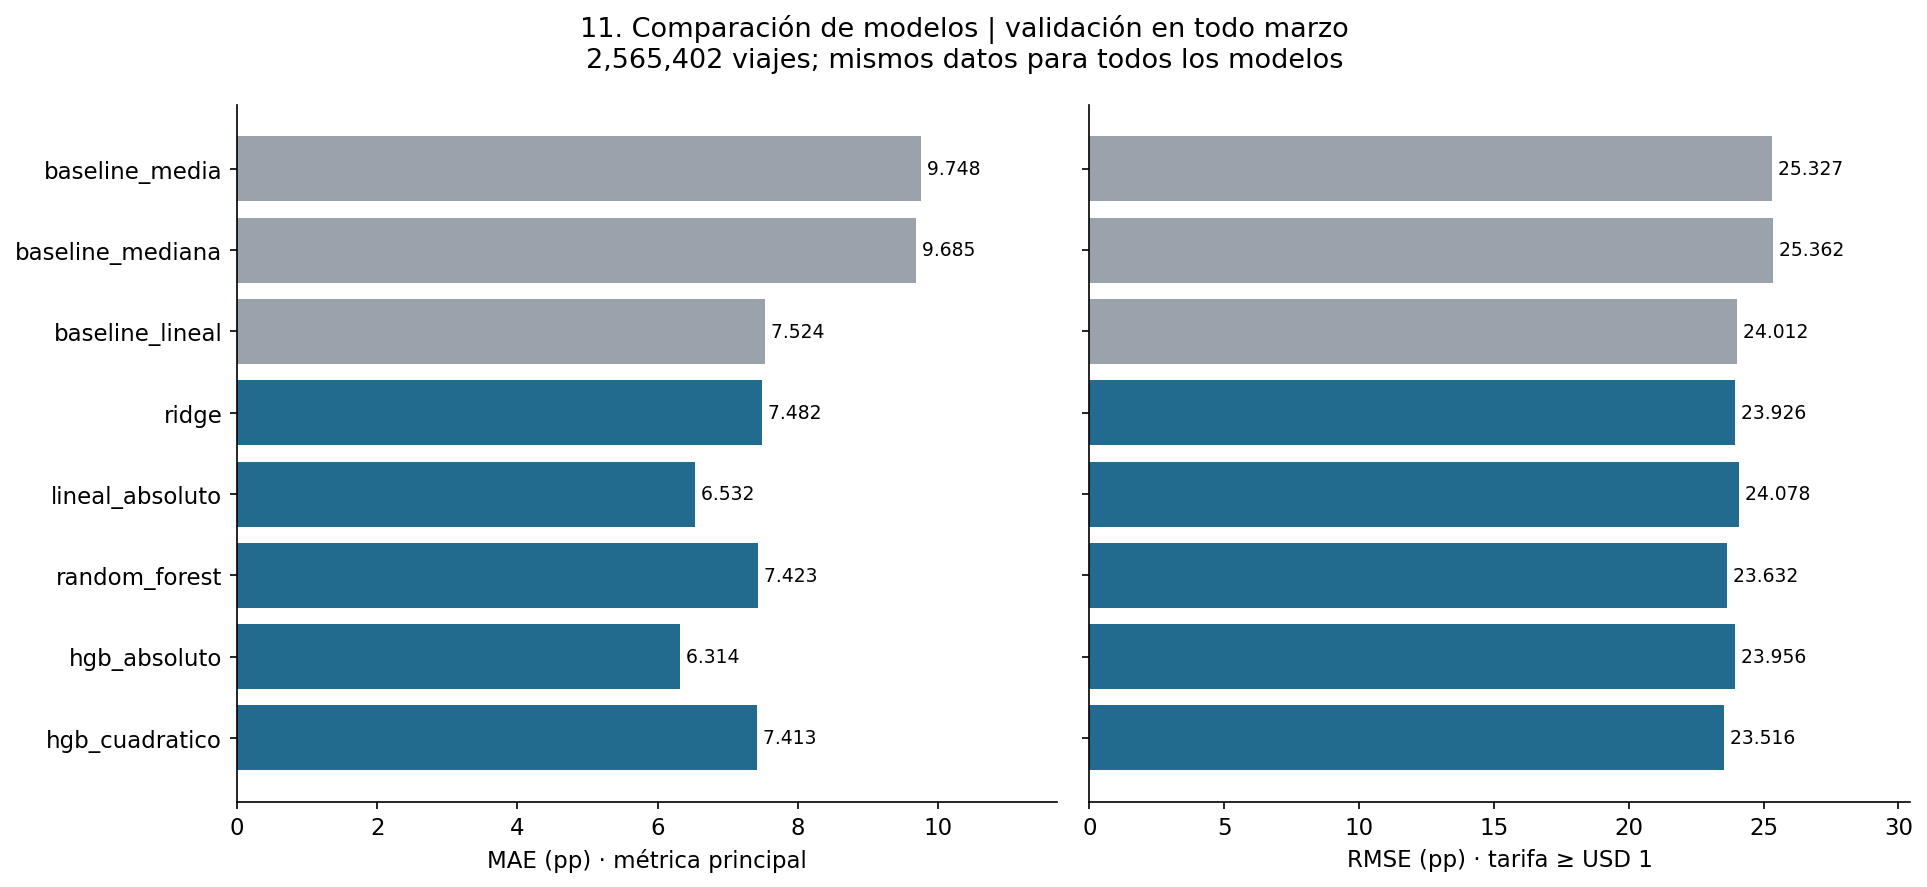

In [3]:
res = pd.DataFrame(val['resultados']).T.drop(columns=['params'], errors='ignore')
base = res.loc['baseline_lineal', 'MAE_pp']
res['mejora_MAE_vs_lineal_%'] = (100 * (1 - res['MAE_pp'] / base)).round(2)
display(res)
print('Modelo elegido (menor MAE en marzo):', val['mejor_modelo'], val['parametros_elegidos'][val['mejor_modelo']])
print('Mejora frente al baseline lineal:', val['mejora_mae_vs_baseline_lineal_pct'], '%')
print('Mejora frente a la mediana:', val['mejora_mae_vs_baseline_mediana_pct'], '%')
display(Image(filename=str(FIG / '11_comparacion_modelos_validacion.png')))

### Lectura

- **Pérdida absoluta vs. cuadrática.** El MAE se minimiza prediciendo la *mediana* condicional. El objetivo es muy asimétrico
  (≈10% de ceros y una cola de miles de por ciento), así que la media condicional queda lejos de la mediana. Ridge, random forest
  y HGB cuadrático estiman la media y apenas mejoran al baseline lineal en MAE, aunque sí reducen la RMSE. Los dos modelos con
  pérdida absoluta son los que más reducen el MAE.
- **Familias.** Con la misma pérdida absoluta, el boosting supera a la regresión L1: captura interacciones (tarifa × recargos ×
  código de tarifa) que el modelo aditivo no representa.
- **MedAE.** El modelo elegido tiene una mediana del error absoluto de ~0.1 pp: para la mitad de los viajes acierta casi exactamente
  el porcentaje, porque muchos pasajeros eligen un botón fijo de la pantalla. El MAE está dominado por los ceros y por la cola.
- **RMSE.** Se mantiene cerca de 107 pp en todos los modelos por los 18 viajes de marzo con tarifa de hasta USD 1 (objetivos de hasta
  140 000%). Por eso se informa también la RMSE con tarifa ≥ USD 1, como en la entrega 1; es un diagnóstico, no la métrica principal.

## 4. Ablación: ¿cuánto aportan los recargos?

In [4]:
abl = val['ablacion_sin_variables_de_cobro']
mejor = val['resultados'][val['mejor_modelo']]
t = pd.DataFrame({f"{val['mejor_modelo']} con recargos": mejor, f"{abl['modelo_base']} sin recargos": abl}).T
display(t[['MAE_pp', 'RMSE_pp', 'MedAE_pp', 'P90_AE_pp', 'RMSE_pp_tarifa_ge_1']])
print('Variables quitadas:', abl['variables_quitadas'])
print(f"Aporte de las variables de cobro: {abl['MAE_pp'] - mejor['MAE_pp']:.3f} pp de MAE")
print(f"Mejora sin recargos vs baseline lineal: {100 * (1 - abl['MAE_pp'] / base):.2f}%")

Variables quitadas: ['extra', 'mta_tax', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'subtotal_pre_tip', 'ratio_subtotal_fare']
Aporte de las variables de cobro: 0.160 pp de MAE
Mejora sin recargos vs baseline lineal: 13.95%


,MAE_pp,RMSE_pp,MedAE_pp,P90_AE_pp,RMSE_pp_tarifa_ge_1
hgb_absoluto con recargos,6.3139,107.2321,0.1031,19.1853,23.9557
hgb_absoluto sin recargos,6.4738,107.2552,0.8331,18.7798,23.899


La mayor parte de la mejora frente al baseline viene de cambiar la pérdida y el tipo de modelo; los recargos agregan una mejora
adicional más pequeña pero consistente, y son la variable más importante en la permutación (ver `04_analisis_errores.ipynb`).

## 5. Predicción vs. valor real (validación)

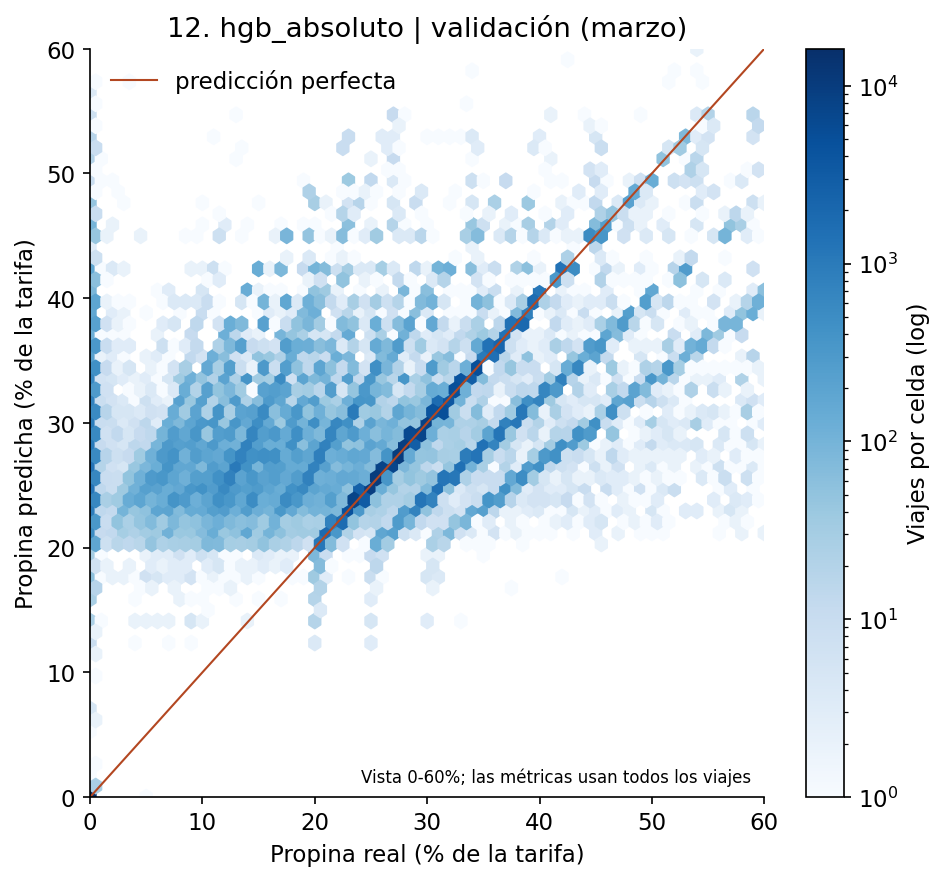

In [5]:
display(Image(filename=str(FIG / '12_pred_vs_real_validacion.png')))

Hay una diagonal muy marcada: para muchos viajes el modelo acierta el porcentaje exacto que resulta de un botón de la pantalla
(20/25/30% del subtotal). Pero las predicciones casi nunca bajan de ~20%: el modelo no reproduce los ceros ni las propinas bajas,
porque la mediana condicional casi nunca lo es. Ese es el principal error sistemático (ver `04_analisis_errores.ipynb`).

## 6. Evaluación final en test (abril), una sola vez

La configuración se fijó con marzo **antes** de leer abril (`metrics_validacion.json` ya contenía el modelo elegido). Se reentrenó con
enero-marzo y se evaluó una vez sobre todos los viajes elegibles de abril.

Modelo final: hgb_absoluto {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'learning_rate': 0.2, 'l2_regularization': 0.0}
Mejora en test frente al baseline lineal: 15.84 %
Mejora en test frente a la mediana: 33.3 %


,n,MAE_pp,RMSE_pp,R2,MedAE_pp,P90_AE_pp,RMSE_pp_tarifa_ge_1
baseline_media,2591610.0,10.1089,654.9891,-0.000000,6.3777,25.2607,24.9242
baseline_mediana,2591610.0,10.0539,654.9900,-0.000003,5.9188,26.3889,24.9729
baseline_lineal,2591610.0,7.9684,654.9165,0.000222,4.3949,17.3223,23.6253
hgb_absoluto,2591610.0,6.7061,654.9238,0.000200,0.1516,19.0328,23.6846


,validación (marzo),test (abril)
baseline_media,9.7479,10.1089
baseline_mediana,9.6848,10.0539
baseline_lineal,7.5237,7.9684
hgb_absoluto,6.3139,6.7061


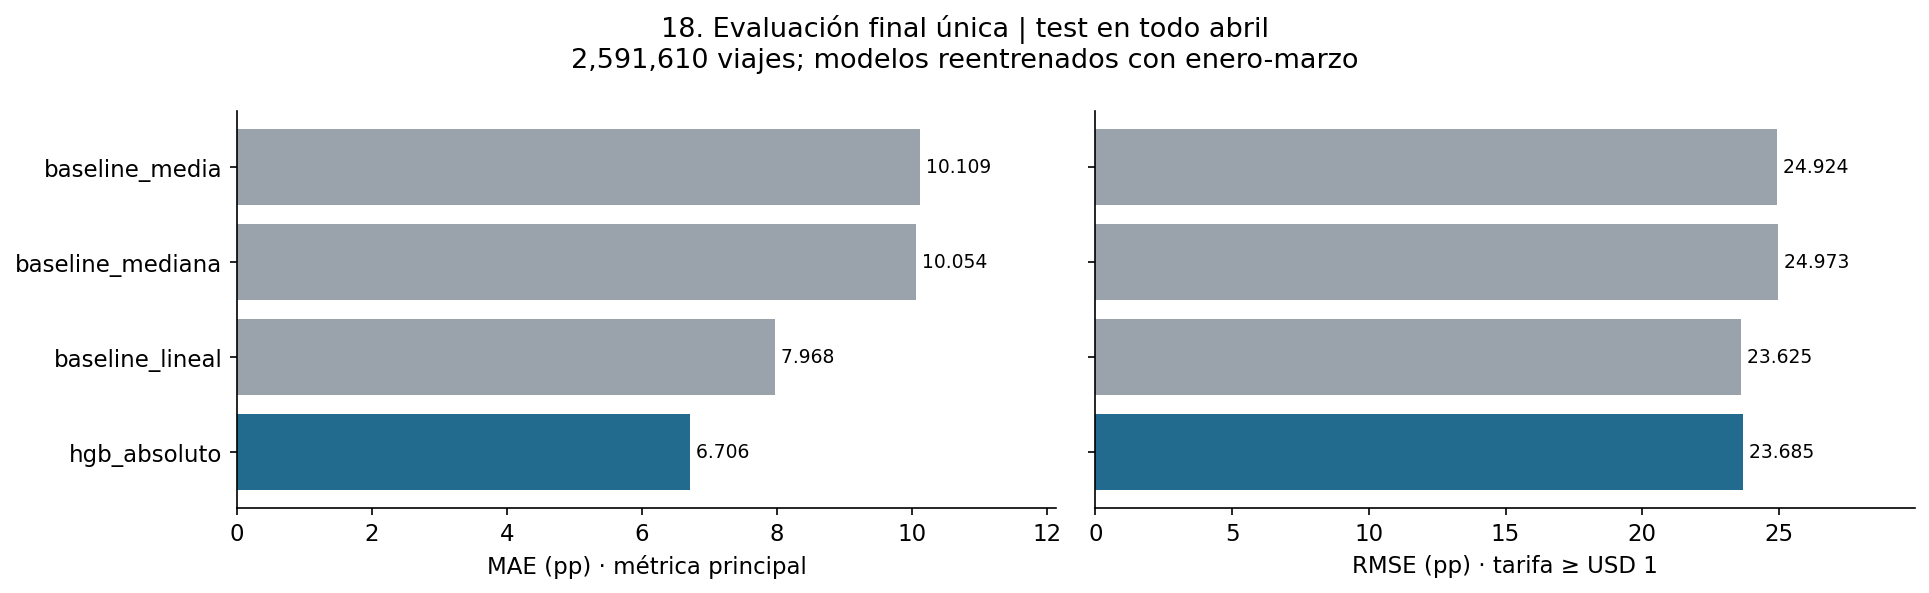

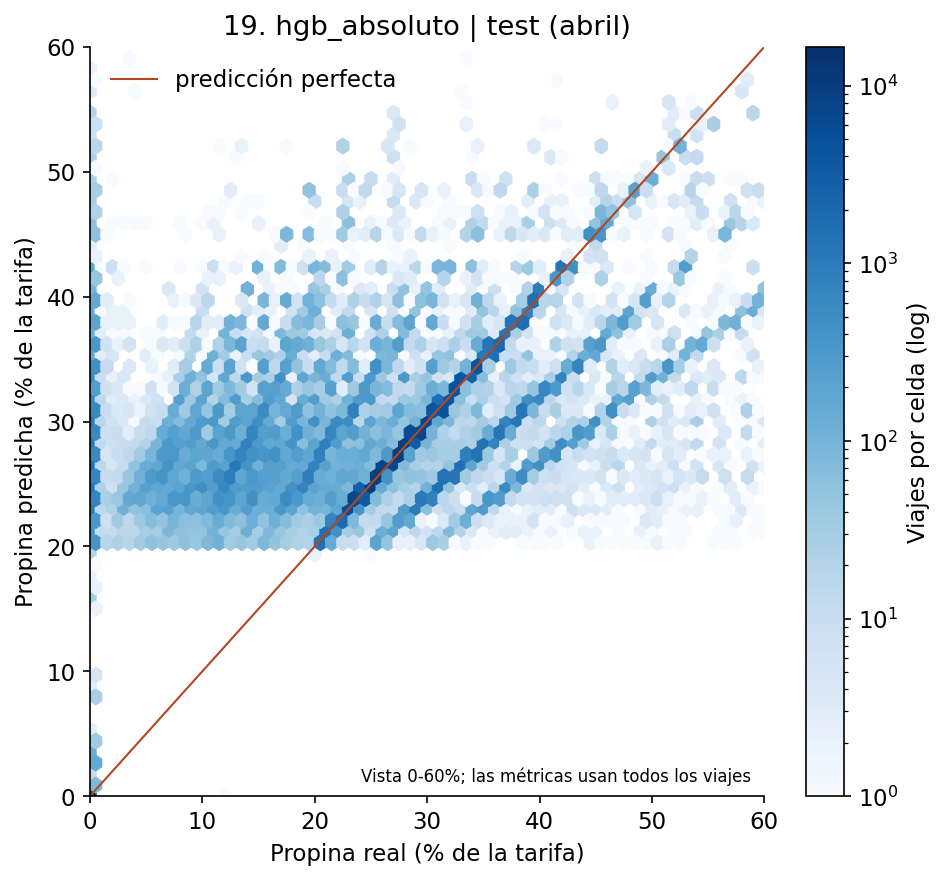

In [6]:
if test is None:
    print('Aún no se ejecutó la etapa test.')
else:
    tt = pd.DataFrame(test['resultados']).T
    display(tt)
    print('Modelo final:', test['modelo_final'], test['parametros'])
    print('Mejora en test frente al baseline lineal:', test['mejora_mae_vs_baseline_lineal_pct'], '%')
    print('Mejora en test frente a la mediana:', test['mejora_mae_vs_baseline_mediana_pct'], '%')
    comp = pd.DataFrame({'validación (marzo)': {k: val['resultados'][k]['MAE_pp'] for k in tt.index},
                         'test (abril)': tt['MAE_pp']})
    display(comp)
    display(Image(filename=str(FIG / '18_comparacion_test.png')))
    display(Image(filename=str(FIG / '19_pred_vs_real_test.png')))

### Lectura del test

- El orden de los modelos se mantiene: el modelo final reduce el MAE en abril aproximadamente en la misma proporción que en marzo
  frente al baseline lineal (≈16%) y frente a la mediana (≈33-35%). La elección hecha en validación fue estable.
- Todos los modelos, incluidos los baselines, empeoran algunas décimas en abril: la proporción de propinas cero sube a ≈10.1%
  (9.9% en marzo), y los ceros son el error dominante. Es una deriva leve del objetivo, no un sobreajuste a marzo.
- La RMSE de abril (~655 pp) es mucho mayor que la de marzo porque abril contiene viajes con tarifa casi nula y porcentajes
  extremos. Con tarifa ≥ USD 1 la RMSE queda en el mismo rango que en marzo. Ese número no cambió ninguna decisión: abril se
  evaluó una sola vez.